Saving cities.txt to cities (3).txt
Generation 0: Best distance = 837.87
Generation 100: Best distance = 435.69
Generation 200: Best distance = 431.24
Generation 300: Best distance = 430.00
Generation 400: Best distance = 430.00

Best route: [18, 12, 16, 5, 8, 3, 15, 4, 6, 1, 0, 17, 13, 9, 11, 2, 10, 7, 14, 19]
Best distance: 430.00


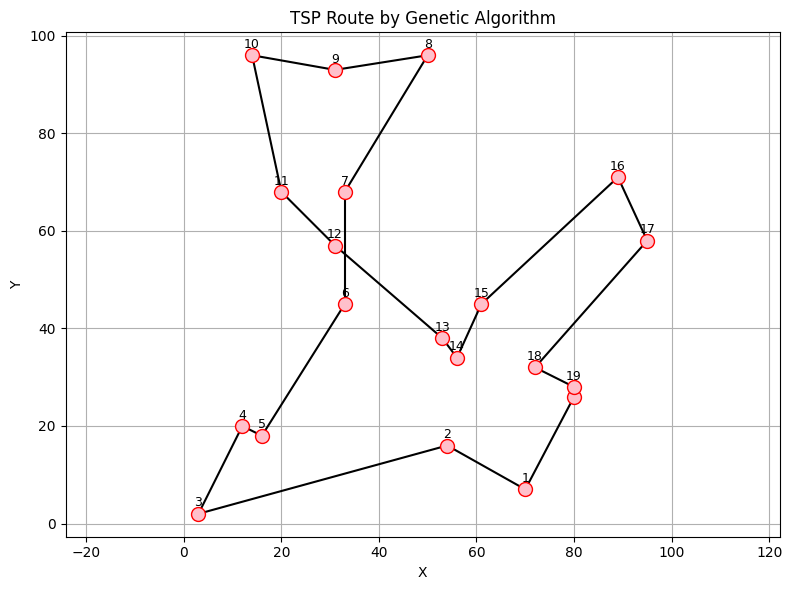

In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# بارگذاری فایل مختصات شهرها
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

# خواندن مختصات شهرها
coords = []
with open(file_name, 'r') as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) == 2:
            coords.append([float(parts[0]), float(parts[1])])
coords = np.array(coords)

# تنظیمات الگوریتم ژنتیک
population_size = 100
num_generations = 500
mutation_rate = 0.01
elite_size = 20

# محاسبه فاصله بین دو شهر
def calculate_distance(city1, city2):
    return np.linalg.norm(np.array(city1) - np.array(city2))

# محاسبه طول کل مسیر
def calculate_total_distance(route, coords):
    return sum(calculate_distance(coords[route[i]], coords[route[(i + 1) % len(route)]]) for i in range(len(route)))

# ایجاد یک فرد (مسیر تصادفی)
def create_individual(n):
    ind = list(range(n))
    random.shuffle(ind)
    return ind

# ایجاد جمعیت اولیه
def create_population(pop_size, n):
    return [create_individual(n) for _ in range(pop_size)]

# رتبه‌بندی افراد بر اساس برازش
def rank_individuals(population, coords):
    fitness = {i: 1 / calculate_total_distance(ind, coords) for i, ind in enumerate(population)}
    return sorted(fitness.items(), key=lambda x: x[1], reverse=True)

# انتخاب افراد برتر
def selection(ranked, elite_size):
    selected = [ranked[i][0] for i in range(elite_size)]
    df = pd.DataFrame(ranked, columns=["Index", "Fitness"])
    df["CumSum"] = df["Fitness"].cumsum()
    df["CumPerc"] = 100 * df["CumSum"] / df["Fitness"].sum()
    for _ in range(len(ranked) - elite_size):
        pick = 100 * random.random()
        for i in range(len(ranked)):
            if pick <= df["CumPerc"][i]:
                selected.append(ranked[i][0])
                break
    return selected

# ساخت استخر جفت‌گیری
def mating_pool(pop, selected):
    return [pop[i] for i in selected]

# عملگر بازترکیب
def breed(p1, p2):
    a, b = sorted([random.randint(0, len(p1)-1) for _ in range(2)])
    childP1 = p1[a:b]
    childP2 = [i for i in p2 if i not in childP1]
    return childP1 + childP2

# ایجاد نسل جدید با بازترکیب
def breed_population(pool, elite_size):
    children = pool[:elite_size]
    pool = random.sample(pool, len(pool))
    for i in range(len(pool) - elite_size):
        children.append(breed(pool[i], pool[-i-1]))
    return children

# عملگر جهش
def mutate(ind, rate):
    for i in range(len(ind)):
        if random.random() < rate:
            j = random.randint(0, len(ind)-1)
            ind[i], ind[j] = ind[j], ind[i]
    return ind

# جهش روی جمعیت
def mutate_population(pop, rate):
    return [mutate(ind, rate) for ind in pop]

# ساخت نسل بعدی
def next_gen(pop, elite_size, mut_rate, coords):
    ranked = rank_individuals(pop, coords)
    selected = selection(ranked, elite_size)
    mating = mating_pool(pop, selected)
    children = breed_population(mating, elite_size)
    return mutate_population(children, mut_rate)

# اجرای الگوریتم ژنتیک
def genetic_algorithm(coords, pop_size, num_gens, mut_rate, elite_size):
    pop = create_population(pop_size, len(coords))
    for gen in range(num_gens):
        pop = next_gen(pop, elite_size, mut_rate, coords)
        if gen % 100 == 0:
            best_idx = rank_individuals(pop, coords)[0][0]
            dist = calculate_total_distance(pop[best_idx], coords)
            print(f"نسل {gen}: بهترین فاصله = {dist:.2f}")
    best_idx = rank_individuals(pop, coords)[0][0]
    return pop[best_idx]

# رسم مسیر بهترین جواب
def plot_route(coords, route):
    plt.figure(figsize=(8, 6))
    for i in range(len(route)):
        c1, c2 = coords[route[i]], coords[route[(i + 1) % len(route)]]
        plt.plot([c1[0], c2[0]], [c1[1], c2[1]], 'k-')
    plt.scatter(coords[:, 0], coords[:, 1], c='pink', edgecolors='red', s=100, zorder=5)
    for i, city_index in enumerate(route):
        x, y = coords[city_index]
        plt.text(x, y + 1.5, str(i), fontsize=9, ha='center')
    plt.title("مسیر مسئله فروشنده دوره‌گرد با الگوریتم ژنتیک")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.axis("equal")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# اجرای نهایی و چاپ بهترین مسیر
best_route = genetic_algorithm(coords, population_size, num_generations, mutation_rate, elite_size)
best_distance = calculate_total_distance(best_route, coords)
print(f"\nبهترین مسیر: {best_route}")
print(f"بهترین فاصله: {best_distance:.2f}")
plot_route(coords, best_route)
